# Error analysis

This notebook reads a results database written by `bioeval run` or `bioeval demo` and answers the
three questions a reviewer asks of any benchmark result: **who is ahead**, **is the gap real**, and
**where does each model fail**.

The results shown here come from the offline demo, so the three "models" are simulations
(`mock-strong`, `mock-medium`, `mock-weak`) that degrade the reference answers in known ways.
Point `DB` at your own results database to analyse real models.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

from bioeval import analysis, storage
from bioeval.cli import main as bioeval_cli
from bioeval.scoring.taxonomy import ErrorType

DB = Path("../demo_output/results.db")
if not DB.exists():  # build the demo database quietly the first time
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bioeval_cli(["demo", "--out-dir", str(DB.parent)])

RUN_IDS = analysis.latest_runs(storage.load_runs(DB))
df = storage.load_results(DB, RUN_IDS)
print(f"{len(df)} graded answers: {df['adapter'].nunique()} models x "
      f"{df['question_id'].nunique()} questions")

90 graded answers: 3 models x 30 questions


In [2]:
# Chart colours come from a documented reference palette (light steps, with the dark
# steps alongside). A PNG cannot follow the viewer's theme, so every figure paints its
# own surface instead of being transparent. Set THEME = "dark" for a dark-surface export.
THEME = "light"
PALETTE = {
    "light": dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781",
                  grid="#e1e0d9", axis="#c3c2b7", series="#2a78d6", empty="#f0efec",
                  ramp=["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95",
                        "#0d366b"]),
    "dark": dict(surface="#1a1a19", ink="#ffffff", ink2="#c3c2b7", muted="#898781",
                 grid="#2c2c2a", axis="#383835", series="#3987e5", empty="#383835",
                 ramp=["#104281", "#184f95", "#1c5cab", "#256abf", "#3987e5", "#6da7ec",
                       "#b7d3f6"]),
}
C = PALETTE[THEME]
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "savefig.facecolor": C["surface"], "text.color": C["ink"], "axes.labelcolor": C["ink2"],
    "axes.edgecolor": C["axis"], "xtick.color": C["muted"], "ytick.color": C["muted"],
    "xtick.labelcolor": C["ink2"], "ytick.labelcolor": C["ink2"],
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})

## Who is ahead?

Mean rubric score per model with a 95% bootstrap confidence interval over questions, plus the
component rates behind it. `rating` is a Bradley-Terry strength fitted from head-to-head
comparisons on the same questions.

In [3]:
board = analysis.leaderboard(df)
board

,model,answered,mean_score,ci_low,ci_high,fact_coverage,misconception_rate,instruction_pass,refusal_rate,api_failures,median_latency_ms,rating,win_rate
0,mock-strong,30,0.993,0.978,1.000,0.993,0.000,1.000,0.000,0,0.0,1160.9,0.8
1,mock-medium,30,0.765,0.641,0.879,0.844,0.133,0.800,0.067,0,0.0,1000.0,0.5
2,mock-weak,30,0.505,0.387,0.620,0.631,0.333,0.767,0.100,0,0.0,839.1,0.2


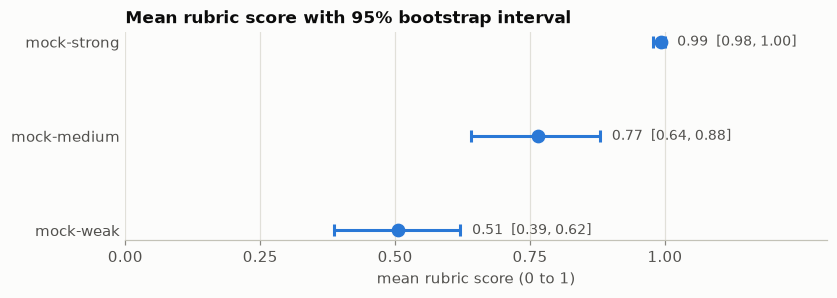

In [4]:
order = board.sort_values("mean_score")  # best model ends up at the top
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(7.5, 2.6), layout="constrained")
ax.errorbar(order["mean_score"], y,
            xerr=[order["mean_score"] - order["ci_low"], order["ci_high"] - order["mean_score"]],
            fmt="o", color=C["series"], markersize=8, elinewidth=2, capsize=4, capthick=2,
            zorder=3)
for yi, row in zip(y, order.itertuples()):
    ax.annotate(f"{row.mean_score:.2f}  [{row.ci_low:.2f}, {row.ci_high:.2f}]",
                (row.ci_high, yi), xytext=(8, 0), textcoords="offset points",
                va="center", color=C["ink2"], fontsize=9)
ax.set_yticks(y, order["model"])
ax.set_xlim(0, 1.3)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel("mean rubric score (0 to 1)")
ax.grid(axis="x", color=C["grid"], linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Mean rubric score with 95% bootstrap interval")
plt.show()

## Is the gap real?

A paired bootstrap over questions: both models answered the same items, so the test resamples
*questions* and compares the two models on each one. If the interval for the difference excludes
zero, the gap is real at this sample size; if it straddles zero, it is not.

In [5]:
analysis.comparisons(df)

,comparison,questions,mean_diff,ci_low,ci_high,p_value,significant
0,mock-strong vs mock-medium,30,0.227,0.113,0.351,< 0.0002,yes
1,mock-strong vs mock-weak,30,0.488,0.374,0.601,< 0.0002,yes


## Where does each model fail?

Each panel counts answers carrying an error label, by subject (one answer can carry several
labels). Darker cells mean more answers; grey tiles mean none. The counts come from a SQL
`GROUP BY` over the `result_errors` table.

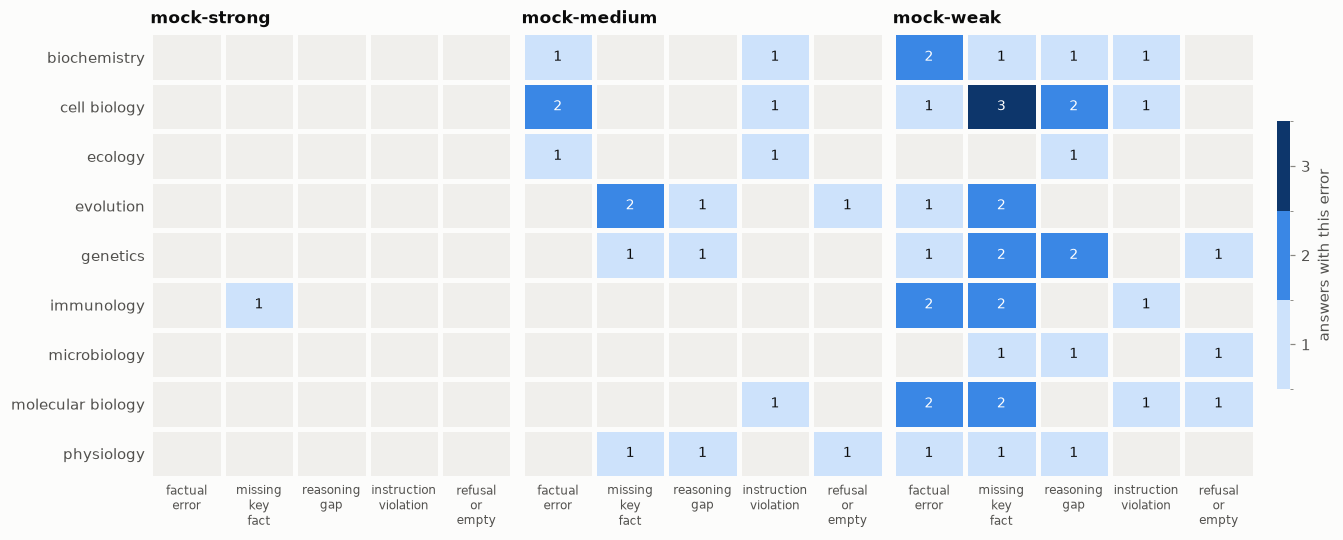

In [6]:
breakdown = storage.error_breakdown(DB, RUN_IDS)
models = board["model"].tolist()  # best first
subjects = sorted(df["subject"].unique())
types = [e.value for e in ErrorType if e.value in set(breakdown["error_type"])]
vmax = max(1, int(breakdown["n"].max()))
cmap = LinearSegmentedColormap.from_list("sequential", C["ramp"])
cmap.set_bad(C["empty"])  # zero counts are masked and drawn as neutral tiles
norm = BoundaryNorm(np.arange(0.5, vmax + 1.5), cmap.N)  # one colour step per whole count

fig, axes = plt.subplots(1, len(models), figsize=(3.3 * len(models) + 2.2, 4.8),
                         sharey=True, squeeze=False, layout="constrained")
for ax, model in zip(axes[0], models):
    grid = (breakdown[breakdown["adapter"] == model]
            .pivot_table(index="subject", columns="error_type", values="n",
                         aggfunc="sum", fill_value=0)
            .reindex(index=subjects, columns=types, fill_value=0))
    values = grid.to_numpy()
    mesh = ax.pcolormesh(np.ma.masked_equal(values, 0), cmap=cmap, norm=norm,
                         edgecolors=C["surface"], linewidth=2)
    for (i, j), v in np.ndenumerate(values):
        if v:
            r, g, b, _ = cmap(norm(v))
            light_cell = 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.5
            ax.text(j + 0.5, i + 0.5, int(v), ha="center", va="center", fontsize=9,
                    color="#0b0b0b" if light_cell else "#ffffff")
    ax.set_title(model)
    ax.set_xticks(np.arange(len(types)) + 0.5, [t.replace("_", "\n") for t in types],
                  fontsize=8)
    ax.set_yticks(np.arange(len(subjects)) + 0.5, [s.replace("_", " ") for s in subjects])
    ax.set_ylim(len(subjects), 0)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(mesh, ax=axes[0].tolist(), shrink=0.6, pad=0.02,
                    ticks=range(1, vmax + 1))
cbar.set_label("answers with this error")
cbar.outline.set_visible(False)
plt.show()

The same counts as a table, totalled over subjects:

In [7]:
analysis.error_counts(df)

errors,factual_error,missing_key_fact,reasoning_gap,instruction_violation,refusal_or_empty
adapter,,,,,
mock-medium,4,4,3,4,2
mock-strong,0,1,0,0,0
mock-weak,10,14,8,4,3


## The lowest-scoring answers

The rubric records *why* each answer lost points, which is what turns a score into feedback.

In [8]:
for row in analysis.worst_answers(df, n=5).itertuples():
    print(f"{row.question_id} | {row.adapter} | score {row.score:.2f} | {', '.join(row.errors)}")
    print("   ", row.response[:240].replace("\n", " "), "\n")

evo-001 | mock-medium | score 0.00 | missing_key_fact, reasoning_gap
    No. 

evo-002 | mock-medium | score 0.00 | refusal_or_empty
    I'm unable to answer that question. 

gen-004 | mock-weak | score 0.00 | refusal_or_empty
    I'm unable to answer that question. 

micro-003 | mock-weak | score 0.00 | refusal_or_empty
    I'm unable to answer that question. 

mol-005 | mock-weak | score 0.00 | refusal_or_empty
    I'm unable to answer that question. 



## Reading real results

* With 30 questions the intervals are wide: a gap of a few points between two real models is
  usually not significant. Check the paired comparison before calling a winner.
* The pattern rubric is literal. A correct answer in unexpected wording can miss a key fact, so for
  real models run with `--judge` and look at the rubric-vs-judge agreement in the HTML report.
* Low scores cluster by subject; read those answers before concluding a model is weak at a topic.
  It may be the rubric, not the model, and the fix belongs in the dataset.